In [ ]:
import sys
import os

# Проверяем, запущен ли ноутбук в среде Google Colab
if "google.colab" in sys.modules:
    !pip install uv -q
    !wget https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_10/pyproject.toml -q
    !uv pip install -r pyproject.toml --system -q
    os.kill(os.getpid(), 9)  # force runtime restart


# 4. Практика на M5 CA_1: иерархия с прерывистым низом

**Сквозной вопрос блока:** прогнозы уровней не складываются — как сделать их согласованными и при этом точнее?

В этом ноутбуке:
- иерархия магазина CA_1: total → категория (3) → отдел (7) → товар (3049); агрегаты ровные, низ прерывистый;
- разные базовые модели по уровням: ETS для агрегатов, Croston SBA / TSB для товаров;
- BU vs TD vs MiddleOut vs MinT shrink: какой уровень делать базовым;
- когда агрегирование помогает прогнозировать прерывистый низ — разбивка по классам спроса;

In [1]:
import warnings
warnings.filterwarnings('ignore')

from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsforecast import StatsForecast
from statsforecast.models import AutoETS, CrostonSBA, TSB
from hierarchicalforecast.utils import aggregate
from hierarchicalforecast.core import HierarchicalReconciliation
from hierarchicalforecast.methods import BottomUp, TopDown, MiddleOut, MinTrace
from hierarchicalforecast.evaluation import evaluate
from utilsforecast.losses import rmsse, bias

plt.rcParams['figure.figsize'] = (12, 4)

H = 28          # горизонт, как в M5
INSAMPLE = 364  # последние дни обучения для долей и ковариации остатков

## 0. Данные

M5, магазин CA_1, дневные продажи 3049 товаров. Иерархия задаётся полями `cat_id` (3 категории)
и `dept_id` (7 отделов).

In [2]:
sales = pd.read_csv('https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_10/data/sales_train_validation.csv.gz')
calendar = pd.read_csv('https://raw.githubusercontent.com/alex-hse-repository/time-series-cu-2026/refs/heads/main/week_10/data/calendar.csv', parse_dates=['date'])

sales_ca1 = sales[sales['store_id'] == 'CA_1']
day_cols = [c for c in sales_ca1.columns if c.startswith('d_')]

bottom = (sales_ca1.melt(id_vars=['item_id', 'dept_id', 'cat_id'], value_vars=day_cols,
                         var_name='d', value_name='y')
          .merge(calendar[['d', 'date']], on='d')
          .rename(columns={'date': 'ds'}))
bottom['total'] = 'total'

spec = [
    ['total'],
    ['total', 'cat_id'],
    ['total', 'cat_id', 'dept_id'],
    ['total', 'cat_id', 'dept_id', 'item_id'],
]
Y_df, S_df, tags = aggregate(bottom[['ds', 'y', 'total', 'cat_id', 'dept_id', 'item_id']], spec)

print({level: len(ids) for level, ids in tags.items()})
print(f'Период: {Y_df["ds"].min().date()} — {Y_df["ds"].max().date()}')

{'total': 1, 'total/cat_id': 3, 'total/cat_id/dept_id': 7, 'total/cat_id/dept_id/item_id': 3049}
Период: 2011-01-29 — 2016-04-24


## 1. Агрегаты ровные, низ прерывистый

Доля нулевых дней по уровням иерархии.

In [3]:
zero_share = Y_df.assign(is_zero=Y_df['y'] == 0).groupby('unique_id')['is_zero'].mean()
pd.DataFrame({
    'рядов': {level: len(ids) for level, ids in tags.items()},
    'средняя доля нулей': {level: zero_share.loc[ids].mean() for level, ids in tags.items()},
}).round(3)

,рядов,средняя доля нулей
total,1,0.003
total/cat_id,3,0.003
total/cat_id/dept_id,7,0.003
total/cat_id/dept_id/item_id,3049,0.639


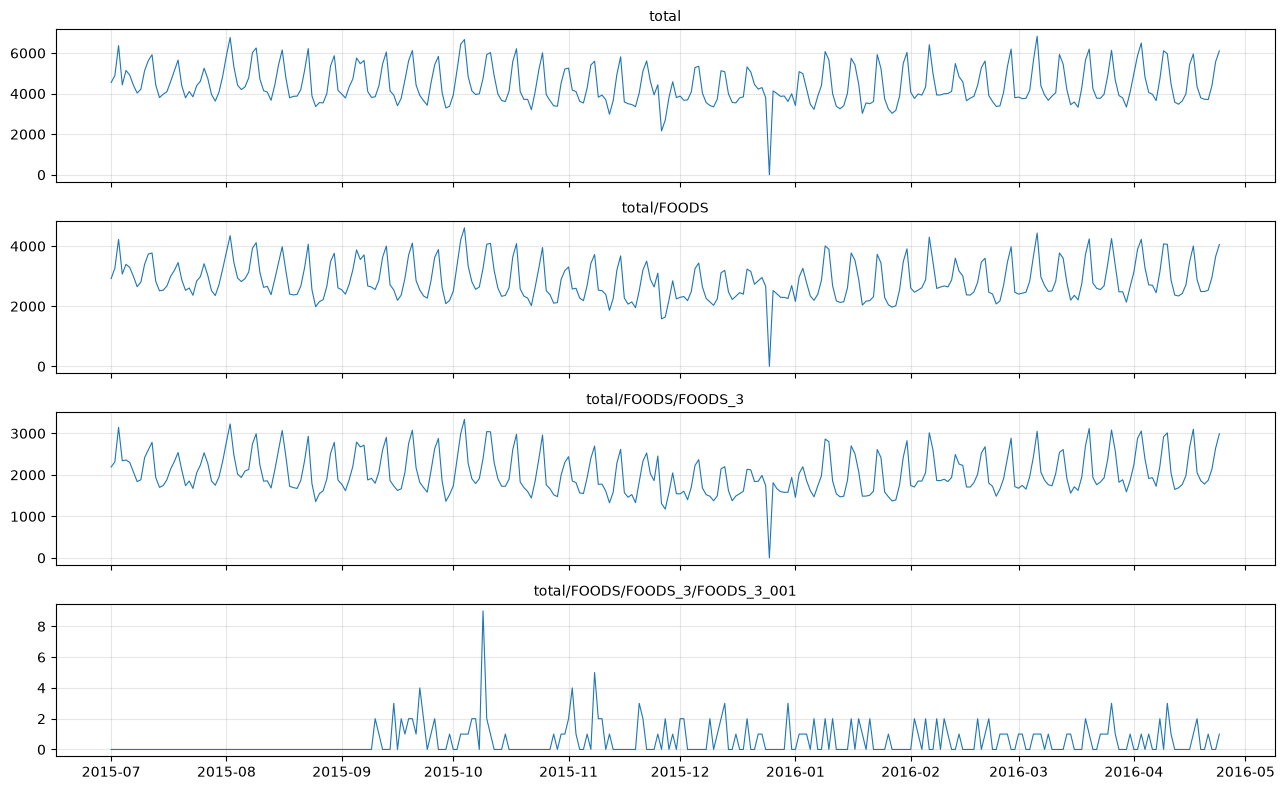

In [4]:
examples = ['total', 'total/FOODS', 'total/FOODS/FOODS_3', 'total/FOODS/FOODS_3/FOODS_3_001']
fig, axes = plt.subplots(len(examples), 1, figsize=(13, 8), sharex=True)
for ax, uid in zip(axes, examples):
    s = Y_df[(Y_df['unique_id'] == uid) & (Y_df['ds'] >= '2015-07-01')]
    ax.plot(s['ds'], s['y'], linewidth=0.8)
    ax.set_title(uid, fontsize=10)
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

На агрегатах — недельная сезонность и тренд, на них хорошо работает ETS. У товаров — нули и редкие продажи,
ETS тут бесполезен, нужен Croston/TSB. Значит, **базовые модели должны быть разными на разных уровнях**,
а согласование соберёт их в единую иерархию.

## 2. Базовые прогнозы по уровням

- агрегаты (11 рядов): `AutoETS(season_length=7)`;
- товары (3049 рядов): `CrostonSBA` и `TSB` — два варианта нижнего уровня.

Прогнозы на обучении (`fitted=True`) нужны для долей top-down и ковариации остатков MinT.

In [5]:
cutoff = Y_df['ds'].max() - pd.Timedelta(days=H)
Y_train = Y_df[Y_df['ds'] <= cutoff]
Y_test = Y_df[Y_df['ds'] > cutoff]

is_item = Y_train['unique_id'].isin(tags['total/cat_id/dept_id/item_id'])

sf_agg = StatsForecast(models=[AutoETS(season_length=7)], freq='D', n_jobs=1)
fc_agg = sf_agg.forecast(df=Y_train[~is_item], h=H, fitted=True)
fit_agg = sf_agg.forecast_fitted_values()

sf_item = StatsForecast(models=[CrostonSBA(), TSB(alpha_d=0.1, alpha_p=0.1)], freq='D', n_jobs=1)
fc_item = sf_item.forecast(df=Y_train[is_item], h=H, fitted=True)
fit_item = sf_item.forecast_fitted_values()

Собираем два набора базовых прогнозов: «ETS + SBA» и «ETS + TSB». На агрегатах они совпадают.

In [6]:
def combine(fc_agg, fc_item):
    agg = fc_agg.assign(SBA=fc_agg['AutoETS'], TSB=fc_agg['AutoETS']).drop(columns='AutoETS')
    return pd.concat([agg, fc_item.rename(columns={'CrostonSBA': 'SBA'})], ignore_index=True)


Y_hat = combine(fc_agg, fc_item)
Y_fitted = combine(fit_agg, fit_item)
Y_fitted = Y_fitted[Y_fitted['ds'] > cutoff - pd.Timedelta(days=INSAMPLE)]   # последний год обучения

Y_hat.head()

,unique_id,ds,SBA,TSB
0,total,2016-03-28,4310.695312,4310.695312
1,total,2016-03-29,3833.678223,3833.678223
2,total,2016-03-30,3769.607422,3769.607422
3,total,2016-03-31,3725.194092,3725.194092
4,total,2016-04-01,4216.806152,4216.806152


## 3. BU vs TD vs MiddleOut vs MinT

- **BU** — базовый уровень товары (Croston/TSB), агрегаты — сумма;
- **TD** — базовый уровень total (ETS), доли товаров — `proportion_averages` за последний год;
- **MiddleOut** — базовый уровень отделы (ETS), вниз — доли, вверх — сумма;
- **MinT shrink** — все уровни сразу.

Ковариация остатков MinT для 3060 рядов по 364 дням вырождена — без shrinkage не обойтись.

In [7]:
reconcilers = [
    BottomUp(),
    TopDown(method='proportion_averages'),
    MiddleOut(middle_level='total/cat_id/dept_id', top_down_method='proportion_averages'),
    MinTrace(method='mint_shrink'),
]
hrec = HierarchicalReconciliation(reconcilers=reconcilers)
Y_rec = hrec.reconcile(Y_hat_df=Y_hat, Y_df=Y_fitted, S_df=S_df, tags=tags)


def short_name(col):
    return (col.replace('/BottomUp', ' BU')
               .replace('/TopDown_method-proportion_averages', ' TD')
               .replace('/MiddleOut_middle_level-total/cat_id/dept_id_top_down_method-proportion_averages', ' MiddleOut')
               .replace('/MinTrace_method-mint_shrink', ' MinT'))


Y_rec = Y_rec.rename(columns=short_name)
models = [c for c in Y_rec.columns if c not in ('unique_id', 'ds')]
models

['SBA',
 'TSB',
 'SBA BU',
 'TSB BU',
 'SBA TD',
 'TSB TD',
 'SBA MiddleOut',
 'TSB MiddleOut',
 'SBA MinT',
 'TSB MinT']

TD и MiddleOut раздают вниз прогноз ETS, поэтому от варианта нижней модели (SBA или TSB) не зависят —
оставим по одной копии.

In [8]:
models = [m for m in models if m not in ('TSB TD', 'TSB MiddleOut')]
Y_rec = Y_rec.rename(columns={'SBA TD': 'TD', 'SBA MiddleOut': 'MiddleOut', 'SBA': 'Base SBA', 'TSB': 'Base TSB'})
models = ['Base SBA', 'Base TSB', 'SBA BU', 'TSB BU', 'TD', 'MiddleOut', 'SBA MinT', 'TSB MinT']

print('Отрицательных прогнозов MinT:', {m: int((Y_rec[m] < 0).sum()) for m in ['SBA MinT', 'TSB MinT']})

Отрицательных прогнозов MinT: {'SBA MinT': 332, 'TSB MinT': 5120}


MinT поправляет и товары — часть прогнозов уходит в минус. Для спроса обрежем их нулём
(`nonnegative=True` на 3049 нижних рядах — квадратичная задача, слишком медленно для семинара).
После обрезки иерархия слегка рассогласуется — честная цена простого решения.

In [9]:
Y_rec[['SBA MinT', 'TSB MinT']] = Y_rec[['SBA MinT', 'TSB MinT']].clip(lower=0)

### Метрики по уровням

Как и в блоке про прерывистый спрос — RMSSE (масштаб — наивный прогноз на обучении) и bias
(среднее «прогноз − факт»). Для масштаба RMSSE обрезаем ведущие нули: до начала продаж товара наивная
ошибка нулевая и искусственно уменьшает знаменатель.

In [10]:
first_sale = Y_train[Y_train['y'] > 0].groupby('unique_id')['ds'].min()
Y_train_trim = Y_train[Y_train['ds'] >= Y_train['unique_id'].map(first_sale)]

Y_eval = Y_rec.merge(Y_test, on=['unique_id', 'ds'])
evaluation = evaluate(Y_eval, metrics=[partial(rmsse, seasonality=1), bias],
                      tags=tags, models=models, train_df=Y_train_trim)
table_rmsse = evaluation[evaluation['metric'] == "rmsse"].drop(columns='metric').set_index('level')
table_bias = evaluation[evaluation['metric'] == "bias"].drop(columns='metric').set_index('level')

In [11]:
table_rmsse.style.format('{:.3f}').highlight_min(axis=1, color='lightgreen')

,Base SBA,Base TSB,SBA BU,TSB BU,TD,MiddleOut,SBA MinT,TSB MinT
level,,,,,,,,
total,0.405,0.405,1.110,1.111,0.405,0.404,0.463,0.479
total/cat_id,0.538,0.538,1.092,1.088,0.508,0.547,0.587,0.595
total/cat_id/dept_id,0.984,0.984,1.176,1.146,0.702,0.984,0.851,0.822
total/cat_id/dept_id/item_id,0.740,0.715,0.740,0.715,0.729,0.734,0.731,0.706
Overall,0.740,0.715,0.741,0.716,0.729,0.735,0.731,0.706


In [12]:
table_bias

,Base SBA,Base TSB,SBA BU,TSB BU,TD,MiddleOut,SBA MinT,TSB MinT
level,,,,,,,,
total,-129.601737,-129.601737,14.699877,26.449522,-129.601737,-120.465100,-157.823232,-156.614177
total/cat_id,-18.633724,-18.633724,4.899959,8.816507,-43.200579,-40.155033,-52.607744,-52.204726
total/cat_id/dept_id,-17.209300,-17.209300,2.099982,3.778503,-18.514534,-17.209300,-22.546176,-22.373454
total/cat_id/dept_id/item_id,0.004821,0.008675,0.004821,0.008675,-0.042506,-0.039510,-0.051458,-0.045967
Overall,-0.095186,-0.091346,0.019216,0.034575,-0.169414,-0.157471,-0.206002,-0.199345


In [13]:
table_bias.abs().style.format('{:.3f}').highlight_min(axis=1, color='lightgreen')

,Base SBA,Base TSB,SBA BU,TSB BU,TD,MiddleOut,SBA MinT,TSB MinT
level,,,,,,,,
total,129.602,129.602,14.700,26.450,129.602,120.465,157.823,156.614
total/cat_id,18.634,18.634,4.900,8.817,43.201,40.155,52.608,52.205
total/cat_id/dept_id,17.209,17.209,2.100,3.779,18.515,17.209,22.546,22.373
total/cat_id/dept_id/item_id,0.005,0.009,0.005,0.009,0.043,0.040,0.051,0.046
Overall,0.095,0.091,0.019,0.035,0.169,0.157,0.206,0.199


### Наблюдения

- **BU плох на агрегатах:** RMSSE 1.11 на total против 0.405 у ETS. Сумма тысяч плоских прогнозов
  Croston/TSB не знает о недельной сезонности. Схема «Croston + bottom-up» из M5 хороша только для самих товаров.
- **TD** (ETS на total + доли за последний год) — лучший на категориях (0.508) и отделах (0.702 против 0.984
  у прямого ETS по отделам). На товарах (0.729) — между SBA и TSB.
- **MinT shrink с TSB** — лучший на товарах (0.706) и улучшает отделы (0.822), но портит total и категории
  (≈ 0.47 против 0.405): шумные остатки 3049 товаров тянут агрегаты. Плюс обрезка отрицательных
  (у TSB MinT их тысячи) слегка рассогласует иерархию.
- **TSB лучше SBA** на товарах (0.715 против 0.740): TSB обновляет вероятность продажи каждый день.
- **Bias** (прогноз − факт): ETS на агрегатах занижает (≈ −130 шт./день на total), и TD / MiddleOut / MinT
  наследуют это занижение; BU, наоборот, немного завышает.
- Строка Overall почти целиком определяется товарами (3049 из 3060 рядов) — смотреть надо по уровням.

**Какой уровень делать базовым:** для отчёта по агрегатам — верхний (TD / прямой ETS), для заказа
товаров — нижний с TSB, а MinT даёт лучший компромисс для нижних уровней.

## 4. Когда агрегирование помогает прерывистому низу

Разобьём товары по классам спроса (ADI / CV² на обучении после первой продажи) и сравним точность
на нижнем уровне: собственная модель товара (BU = базовый Croston/TSB) против долей от агрегата.

In [14]:
items_train = Y_train_trim[Y_train_trim['unique_id'].isin(tags['total/cat_id/dept_id/item_id'])]
nonzero = items_train[items_train['y'] > 0].sort_values(['unique_id', 'ds'])

adi = nonzero.groupby('unique_id')['ds'].diff().dt.days.groupby(nonzero['unique_id']).mean()
cv2 = nonzero.groupby('unique_id')['y'].agg(lambda v: (v.std(ddof=0) / v.mean()) ** 2)

demand_class = pd.Series(
    np.select([(adi < 1.32) & (cv2 < 0.49), (adi >= 1.32) & (cv2 < 0.49), (adi < 1.32) & (cv2 >= 0.49)],
              ['smooth', 'intermittent', 'erratic'], default='lumpy'),
    index=adi.index, name='class')
demand_class.value_counts()

class
intermittent    2191
lumpy            540
smooth           238
erratic           80
Name: count, dtype: int64

In [15]:
item_eval = Y_eval[Y_eval['unique_id'].isin(tags['total/cat_id/dept_id/item_id'])]
item_scores = rmsse(item_eval, models=models, seasonality=1,
                    train_df=items_train).set_index('unique_id').join(demand_class)

by_class = item_scores.groupby('class')[models].mean()
by_class['товаров'] = item_scores['class'].value_counts()
by_class.style.format('{:.3f}').highlight_min(axis=1, color='lightgreen')

,Base SBA,Base TSB,SBA BU,TSB BU,TD,MiddleOut,SBA MinT,TSB MinT,товаров
class,,,,,,,,,
erratic,0.681,0.654,0.681,0.654,0.652,0.673,0.671,0.644,80.000
intermittent,0.745,0.721,0.745,0.721,0.738,0.741,0.739,0.715,2191.000
lumpy,0.699,0.669,0.699,0.669,0.690,0.697,0.691,0.662,540.000
smooth,0.801,0.776,0.801,0.776,0.764,0.779,0.769,0.741,238.000


### Наблюдения

- **smooth и erratic** (частые продажи, ADI < 1.32): доли от агрегата не хуже собственной модели —
  TD 0.764 против 0.776 у TSB (smooth), 0.652 против 0.654 (erratic). Доля такого товара в отделе стабильна,
  а прогноз агрегата знает о сезонности.
- **intermittent и lumpy** (редкие продажи, это 2731 товар из 3049): собственный TSB лучше долей —
  0.721 против 0.738 и 0.669 против 0.690. Средняя доля редкого товара плохо описывает его ближайшие продажи.
- MinT с TSB — лучший во всех четырёх классах: он смешивает обе информации, а не выбирает одну.

**Правило:** агрегирование помогает прерывистому низу, когда продажи частые; для редких товаров нужна
собственная модель (TSB), а лучше — согласование, которое использует оба уровня.

## Итог

| Ситуация | Что делать |
|---|---|
| Агрегаты ровные, низ прерывистый | Разные базовые модели по уровням: ETS наверху, Croston/TSB внизу |
| Нужна точность на агрегатах | Не BU: сумма тысяч Croston-прогнозов теряет сезонность; TD или прямой прогноз |
| Нужна точность на товарах | TSB лучше SBA; доли от агрегата помогают только товарам с частыми продажами |
| Нужен компромисс по всем уровням | MinT shrink + обрезка отрицательных: лучший внизу, но проигрывает наверху |